# Exercise 1 — Point Clouds

Goal: generate 4 Gaussian classes in 2D, then see what happens to their separability as we scale up the spread (std) while keeping the centers fixed.

## Setup
Fixed seed so results are reproducible.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(42)

## Class parameters
Each class has a fixed mean (center) and a base standard deviation. 100 points per class, 4 classes = 400 points total.

In [2]:
CLASSES = {
    0: {"mu": np.array([2.0, 3.0]), "sigma": np.array([0.8, 2.5])},
    1: {"mu": np.array([5.0, 6.0]), "sigma": np.array([1.2, 1.9])},
    2: {"mu": np.array([8.0, 1.0]), "sigma": np.array([0.9, 0.9])},
    3: {"mu": np.array([15.0, 4.0]), "sigma": np.array([0.5, 2.0])},
}
N_PER_CLASS = 100
COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]

## Generator function
`scale` multiplies the standard deviation only — the class centers never move. This is what lets us later study "what happens as classes get more spread out" in isolation, without also changing where they are.

In [3]:
def generate(scale, rng):
    """Sample all four classes with std scaled by `scale`; means are fixed."""
    points, labels = [], []
    for cls, params in CLASSES.items():
        pts = rng.normal(loc=params["mu"], scale=params["sigma"] * scale, size=(N_PER_CLASS, 2))
        points.append(pts)
        labels.append(np.full(N_PER_CLASS, cls))
    return np.vstack(points), np.concatenate(labels)

## Figure 1 — base scatter (s=1.0)
Plot every point colored by class, with an X marking each class's true center. Just eyeballing this tells you a lot about which classes will be easy or hard to separate.

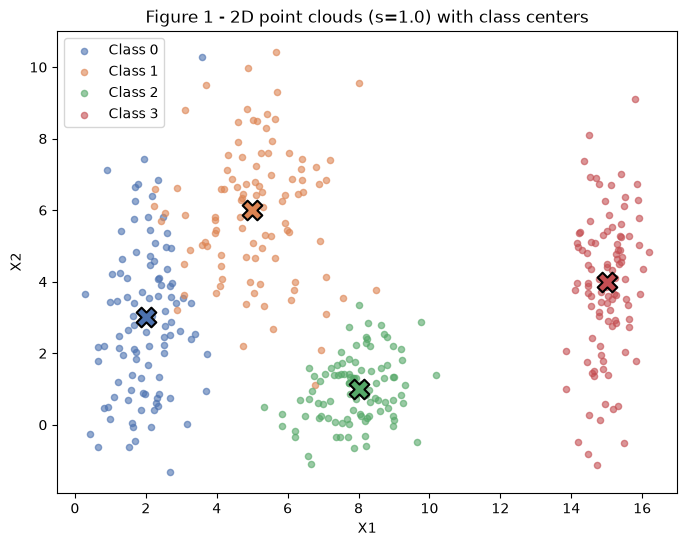

In [4]:
X1, y1 = generate(1.0, rng)
plt.figure(figsize=(8, 6))
for cls in range(4):
    mask = y1 == cls
    plt.scatter(X1[mask, 0], X1[mask, 1], s=20, alpha=0.6, color=COLORS[cls], label=f"Class {cls}")
    plt.scatter(*CLASSES[cls]["mu"], marker="X", s=200, color=COLORS[cls], edgecolor="black", linewidth=1.5)
plt.title("Figure 1 - 2D point clouds (s=1.0) with class centers")
plt.xlabel("X1"); plt.ylabel("X2"); plt.legend()
plt.show()

## Separation ratio r_ij
A single number per class pair that summarizes "how separated are these two classes, relative to how spread out they are?" Formula: `r_ij = ||mu_i - mu_j|| / (sigma_bar_i + sigma_bar_j)`. Big r_ij = well separated, small r_ij = classes likely to overlap. We compute it at a given scale because sigma_bar scales with `s`.

In [5]:
def separation_ratios(scale):
    ratios = {}
    for i in range(4):
        for j in range(i + 1, 4):
            mu_i, mu_j = CLASSES[i]["mu"], CLASSES[j]["mu"]
            sbar_i = CLASSES[i]["sigma"].mean() * scale
            sbar_j = CLASSES[j]["sigma"].mean() * scale
            ratios[(i, j)] = np.linalg.norm(mu_i - mu_j) / (sbar_i + sbar_j)
    return ratios

ratios_s1 = separation_ratios(1.0)
for pair, r in sorted(ratios_s1.items(), key=lambda kv: kv[1]):
    print(f"classes {pair}: r = {r:.4f}")

classes (0, 1): r = 1.3258
classes (1, 2): r = 2.3800
classes (0, 2): r = 2.4802
classes (2, 3): r = 3.5422
classes (1, 3): r = 3.6422
classes (0, 3): r = 4.4960


Classes 0 and 1 come out with the smallest r_ij — meaning they're the pair most likely to overlap, which you can already see by eye in Figure 1.

## Mixing rate
A more direct empirical measure: for every point, find the *nearest* class center (by Euclidean distance). If that nearest center isn't the point's own class, it's "mixed in" with the wrong class. The fraction of mixed points = mixing rate. This is basically what a simple nearest-centroid classifier would get wrong.

In [6]:
def mixing_rate(points, labels):
    centers = np.array([CLASSES[c]["mu"] for c in range(4)])
    dists = np.linalg.norm(points[:, None, :] - centers[None, :, :], axis=2)
    nearest = dists.argmin(axis=1)
    return float((nearest != labels).mean())

print("Mixing rate at s=1.0:", mixing_rate(X1, y1))

Mixing rate at s=1.0: 0.05


## Scaling the spread: s in {0.5, 1.0, 2.0, 4.0}
Now we regenerate the data 4 times, each time multiplying every class's std by a different `s`. Same means, same shapes — just "stretched" clusters. We use one shared x/y axis range across all four subplots so the visual spread is actually comparable (otherwise matplotlib would auto-zoom each panel and hide how much bigger the clusters get).

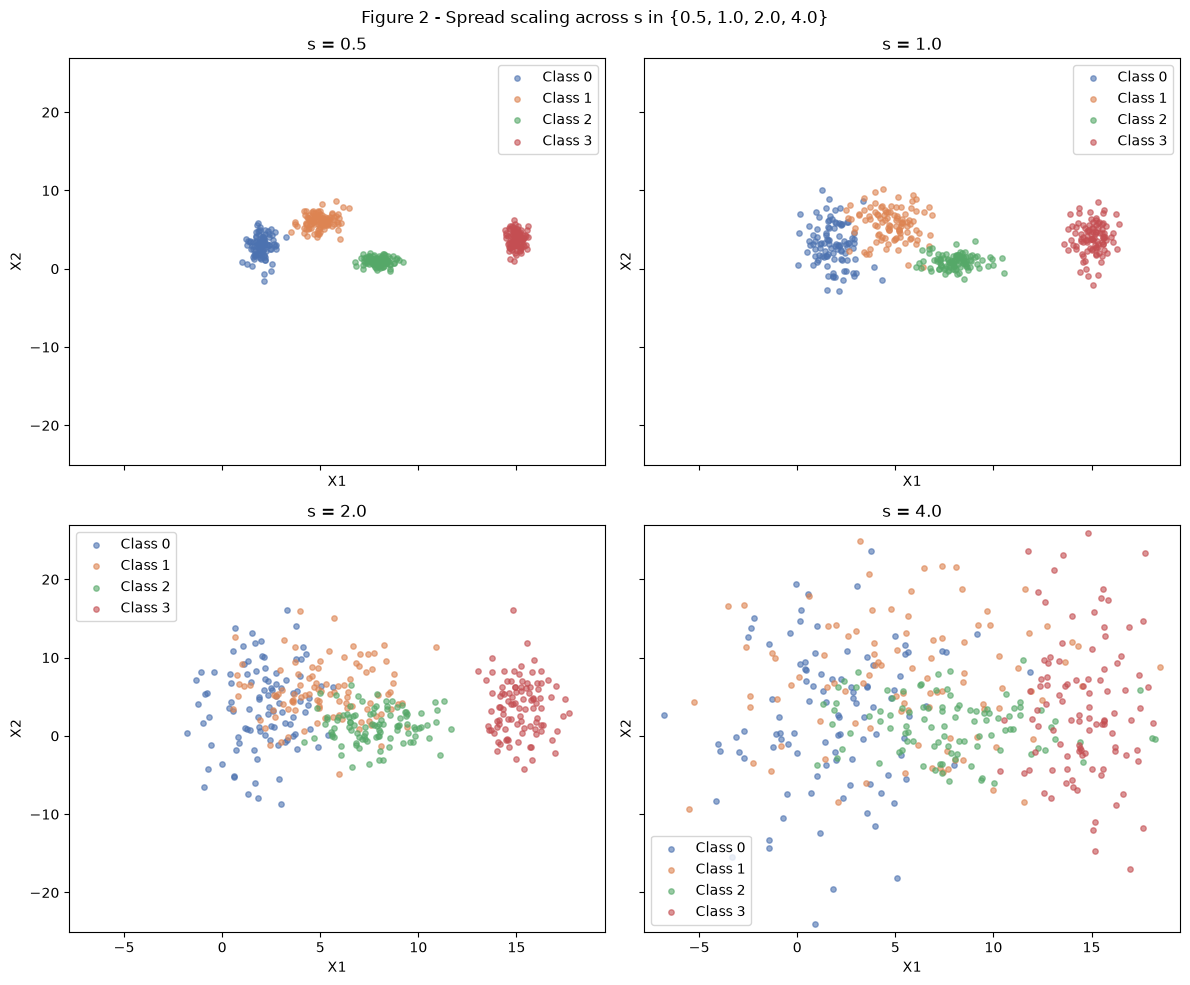

In [7]:
scales = [0.5, 1.0, 2.0, 4.0]
datasets = {s: generate(s, rng) for s in scales}

all_pts = np.vstack([pts for pts, _ in datasets.values()])
xlim = (all_pts[:, 0].min() - 1, all_pts[:, 0].max() + 1)
ylim = (all_pts[:, 1].min() - 1, all_pts[:, 1].max() + 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
for ax, s in zip(axes.ravel(), scales):
    pts, labels = datasets[s]
    for cls in range(4):
        mask = labels == cls
        ax.scatter(pts[mask, 0], pts[mask, 1], s=15, alpha=0.6, color=COLORS[cls], label=f"Class {cls}")
    ax.set_title(f"s = {s}"); ax.set_xlabel("X1"); ax.set_ylabel("X2")
    ax.set_xlim(xlim); ax.set_ylim(ylim); ax.legend()
fig.suptitle("Figure 2 - Spread scaling across s in {0.5, 1.0, 2.0, 4.0}")
fig.tight_layout()
plt.show()

Watch how the clusters visibly bleed into each other as `s` grows — that's the spread scaling overwhelming the fixed distance between the means.

## Putting numbers on that: r_ij at s=2.0, and mixing rate at every scale
Since only sigma scales with `s` (means are fixed), r_ij(s) = r_ij(1) / s exactly — that's why it's a clean halving from s=1 to s=2. Mixing rate, on the other hand, is empirical (it depends on the actual random draw), so we just compute it directly at each scale.

In [8]:
ratios_s2 = separation_ratios(2.0)
print("r_ij at s=2.0:")
for pair, r in sorted(ratios_s2.items(), key=lambda kv: kv[1]):
    print(f"  classes {pair}: r = {r:.4f}")

print()
mixing_rates = {s: mixing_rate(*datasets[s]) for s in scales}
for s in scales:
    print(f"Mixing rate at s={s}: {mixing_rates[s]:.4f}")

r_ij at s=2.0:
  classes (0, 1): r = 0.6629
  classes (1, 2): r = 1.1900
  classes (0, 2): r = 1.2401
  classes (2, 3): r = 1.7711
  classes (1, 3): r = 1.8211
  classes (0, 3): r = 2.2480

Mixing rate at s=0.5: 0.0000
Mixing rate at s=1.0: 0.0675
Mixing rate at s=2.0: 0.2250
Mixing rate at s=4.0: 0.4175


## Figure 3 — mixing rate vs. scale
A single plot tying it together: as the spread scale factor goes up, the mixing rate climbs too. This is the direct empirical evidence for "at some point, a linear/nearest-center boundary stops working."

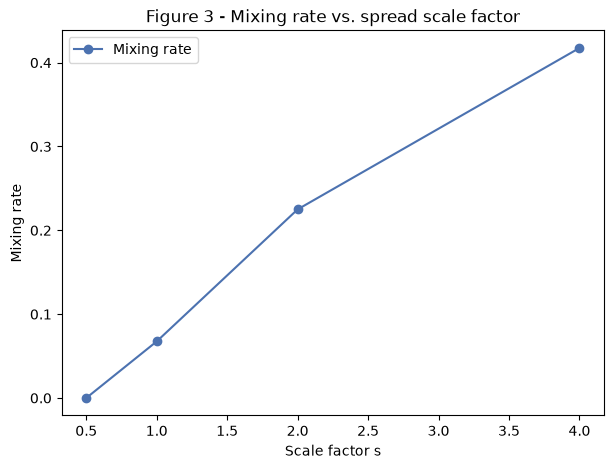

In [9]:
plt.figure(figsize=(7, 5))
plt.plot(scales, [mixing_rates[s] for s in scales], marker="o", color="#4C72B0", label="Mixing rate")
plt.title("Figure 3 - Mixing rate vs. spread scale factor")
plt.xlabel("Scale factor s"); plt.ylabel("Mixing rate"); plt.legend()
plt.show()

## Takeaway
Classes 0 and 1 are the bottleneck pair (smallest r_ij) at every scale. Separability for *all four* classes together is already shaky at s=1.0 (6.75% mixing, driven almost entirely by the 0/1 pair) and clearly breaks down by s=2.0 (22.5% mixing, r_ij for the worst pair drops below 1). By s=4.0 nearly half the points would be misassigned by proximity alone.